<a href="https://colab.research.google.com/github/yakdudi12/IID/blob/main/notebooks/TrabajoFinal_IID.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Declaración de uso de IA:
  Se uso claude Opus 5.5 para ver si la base de datos propuesta cumple con los requisitos para poder realizar el Trabajo Práctico.
  Answer: "Si [...]"

Segundo Prompt: "ES muy pesada la base de datos de clinvar, necesito hacer algo on-demand u online, porque se cierra la sesión de colab".
EL reto de las consultas fueron por el problema que es muy pesada la base de datos y se busca resolver ese problema

Tercer Prompt: SE le pidio a CLaude Opus 5.5 que me liste los requisitos que debo cumplir para el Trabajo final quede acorde. Leyo mi carpeta de la materia completa y todos los trabajos realizados en ella. Y el enunciado del Trabajo. Respuesta: Me dio el checklist de cosas que deberia hacer para llegar hasta 2NF, y algunas recomendaciones.

4rto Prompt: Se le pidio a Claude Opus 5.5 que evalue como se distribuyen los nulls dentro del conjunto de datos, y que devuelva esa información junto a una tabla para tomar decisiones de como resolverlos para cada caso especifico.
  4.2: "❯ Volveme a hacer esta tabla con todas las columnas que poseen nulls explicito, implicitos, estructurales y numéricos, con una breve descripcion del por que consideras
  que son nulls y tu propuesta. Asi tomamos decisiones en conjunto sobre como tratar cada uno de estos casos"

5to prompt: "❯ Ahora tendremos que abordar como elegir la mejor candidata a Primary Key (PK), yo ya previamente habia elegido una en otra iteracion, pero tenemos que
  hacerlo de manera formal ahora (En esa ocasion habia elegido una Composite Key que combinaba el UniProtID o en este caso el "NM" junto con otras
  columnas). Primero Barajemos las SUper Key y determinemos las Candidate Keys a usar, y de ahi elegimos una Primary Key formalmente."

6to prompt: A OPus 5.5 le pase mis requisitos para sea 1NF, y le pregunte si los cumpliamos y que nos faltaba solucionar. Se solucionaron esos hechos, y debido a que nos quedamos con 1 sola PK, 2NF tambien quedo asegurado.

7to prompt: A Opus 5.5: "❯ Preparemos la tabla para avanzar a 3NF. SIguiendo la consigna de " Every non-key attribute in a table should depend on the key, the whole key, and nothing
  but the key". Asi que vamos a ir preparando las subtablas que ya habiamos previsto."

8to prompt: A Opus 5.5: se le pidio que evalue nuestro estado para 4NF en base a la siguiente consigna: "Multivalued dependencies in a table must be multivaluated dependencies on the key".

9no prompt: A Opus 5.5: Una vez normalizada la base de datos, se pidio crear el diagrama de entidad-relacion basandonos en las keys que fuimos generando en cada paso anterior.

In [1]:
%pip install polars graphviz


[notice] A new release of pip is available: 23.0.1 -> 26.3
[notice] To update, run: python -m pip install --upgrade pip


Note: you may need to restart the kernel to use updated packages.


In [2]:
import polars as pl

url = "https://ftp.ncbi.nlm.nih.gov/pub/clinvar/tab_delimited/archive/variant_summary_2026-10.txt.gz"

# Columnas a conservar y su tipo (downcasting: Int32/Int16/Int8 donde el rango alcanza,
# Categorical para texto de baja cardinalidad). El resto de las 43 columnas no se lee.
COLS = {
    "#AlleleID": pl.Int32, "VariationID": pl.Int32, "Type": pl.Categorical, "Name": pl.String,
    "GeneID": pl.Int32, "GeneSymbol": pl.String, "HGNC_ID": pl.String,
    "ClinicalSignificance": pl.Categorical, "ClinSigSimple": pl.Int8, "LastEvaluated": pl.String,
    "PhenotypeIDS": pl.String, "PhenotypeList": pl.String,
    "Origin": pl.Categorical, "OriginSimple": pl.Categorical,
    "Chromosome": pl.Categorical, "Cytogenetic": pl.Categorical, "Start": pl.Int32, "Stop": pl.Int32,
    "ReviewStatus": pl.Categorical, "NumberSubmitters": pl.Int16,
}

df = (pl.scan_csv(url, separator="\t", null_values=["na", "-"], infer_schema=False,
                  schema_overrides={**COLS, "Assembly": pl.Categorical})
        .filter(pl.col("Assembly") == "GRCh38")   # cada variante aparece una vez por ensamblado
        .select(list(COLS))                        # Assembly se usa solo para filtrar
        .with_columns(pl.col("LastEvaluated").str.strptime(pl.Date, "%b %d, %Y"))
        .collect(engine="streaming"))

df.glimpse()

Rows: 4578190
Columns: 20
$ #AlleleID             <i32> 15041, 15042, 15043, 15044, 15045, 15046, 15048, 15049, 15050, 15051
$ VariationID           <i32> 2, 3, 4, 5, 6, 214885, 9, 10, 11, 12
$ Type                  <cat> Indel, Deletion, single nucleotide variant, single nucleotide variant, single nucleotide variant, single nucleotide variant, single nucleotide variant, single nucleotide variant, single nucleotide variant, single nucleotide variant
$ Name                  <str> 'NM_014855.3(AP5Z1):c.80_83delinsTGCTGTAAACTGTAACTGTAAA (p.Arg27_Ile28delinsLeuLeuTer)', 'NM_014855.3(AP5Z1):c.1413_1426del (p.Leu473fs)', 'NM_014630.3(ZNF592):c.3136G>A (p.Gly1046Arg)', 'NM_017547.4(FOXRED1):c.694C>T (p.Gln232Ter)', 'NM_017547.4(FOXRED1):c.1289A>G (p.Asn430Ser)', 'NM_025152.3(NUBPL):c.166G>A (p.Gly56Arg)', 'NM_000410.4(HFE):c.845G>A (p.Cys282Tyr)', 'NM_000410.4(HFE):c.187C>G (p.His63Asp)', 'NM_000410.4(HFE):c.193A>T (p.Ser65Cys)', 'NM_000410.4(HFE):c.314T>C (p.Ile105Thr)'
$ GeneID             

# Selección de columnas y tipos

In [3]:
print(f"Memoria del DataFrame: {df.estimated_size('mb'):,.0f} MB")
df["Type"].value_counts(sort=True)

Memoria del DataFrame: 870 MB


Type,count
cat,u32
"""single nucleotide variant""",4238174
"""Deletion""",173701
"""Duplication""",73911
"""Microsatellite""",40521
"""Indel""",19927
…,…
"""copy number loss""",7234
"""Inversion""",1557
"""Variation""",701


## Motivos: columnas descartadas

| Columna | Justificación |
|---|---|
| `Assembly` | Debido a que solo se uso para filtrar GRCh38 |
| `nsv/esv (dbVar)` | Es un ID externo, con exceso de nulls |
| `RCVaccession` | ID multivalor que posee informacion redudante a otras columnas (PhenotypeList) |
| `ChromosomeAccession` | Redudante si ya fijamos GRCh38 |
| `ReferenceAllele` | No tiene datos |
| `AlternateAllele` | No tiene datos |
| `PositionVCF` | VCF es otro tipo de anotacion de variantes la cual no usamos en este analisis |
| `ReferenceAlleleVCF` | Relacionado con PositionVCF |
| `AlternateAlleleVCF` | Relacionado con PositionVCF |
| `Guidelines` | No se usa |
| `TestedInGTR` | No se usa |
| `OtherIDs` | IDs en otras bases de datos, es multivalor. Pero no lo necesitamos |
| `SubmitterCategories` | NO se usa |
| `SomaticClinicalImpact` | Sin datos |
| `SomaticClinicalImpactLastEvaluated` | NO se usa |
| `ReviewStatusClinicalImpact` | NO se usa |
| `Oncogenicity` | Aplica a solo 1 tipo de variantes |
| `OncogenicityLastEvaluated` | Lo mismo de arriba |
| `ReviewStatusOncogenicity` | Lo mismo de arriba |
| `SCVsForAggregateGermlineClassification` | Redundante (CLinicalSIgnificance y NUmberSUbmitters)|
| `SCVsForAggregateSomaticClinicalImpact` | LO mismo |
| `SCVsForAggregateOncogenicityClassification` | Lo mismo |
| `RS# (dbSNP)` | |


# Valores faltantes

## 1. Nulls explícitos

In [4]:
pl.Config.set_tbl_rows(25)
n = df.height
(df.null_count()
   .transpose(include_header=True, header_name="columna", column_names=["nulos"])
   .with_columns((pl.col("nulos") / n * 100).round(2).alias("pct"))
   .sort("nulos", descending=True))

columna,nulos,pct
str,u32,f64
"""LastEvaluated""",276994,6.05
"""ClinicalSignificance""",244562,5.34
"""ReviewStatus""",244562,5.34
"""PhenotypeIDS""",73955,1.62
"""HGNC_ID""",28729,0.63
"""Cytogenetic""",3140,0.07
"""GeneSymbol""",1661,0.04
"""PhenotypeList""",767,0.02
"""#AlleleID""",0,0.0


## 2. Nulls ocultos (valores centinela)

ClinVar codifica la ausencia de dato con valores que no son null: `-1`, `0` o textos como *not provided*.

In [5]:
SIN_CLASIF = ["not provided", "no classification for the single variant",
              "no classifications from unflagged records"]
SIN_FENO = ["not provided", "not specified"]

(df.select(
    (pl.col("GeneID") == -1).sum().alias("GeneID = -1"),
    (pl.col("ClinSigSimple") == -1).sum().alias("ClinSigSimple = -1"),
    (pl.col("NumberSubmitters") == 0).sum().alias("NumberSubmitters = 0"),
    pl.col("ClinicalSignificance").cast(pl.String).is_in(SIN_CLASIF).sum().alias("ClinicalSignificance sin clasificación"),
    pl.col("PhenotypeList").str.split("|").list.eval(pl.element().is_in(SIN_FENO)).list.all().sum()
      .alias("PhenotypeList solo not provided/specified"),
    pl.col("OriginSimple").cast(pl.String).is_in(["not provided", "unknown", "not applicable"]).sum()
      .alias("OriginSimple sin dato"),
  )
  .transpose(include_header=True, header_name="centinela", column_names=["filas"])
  .with_columns((pl.col("filas") / n * 100).round(2).alias("pct")))

centinela,filas,pct
str,u32,f64
"""GeneID = -1""",28174,0.62
"""ClinSigSimple = -1""",245244,5.36
"""NumberSubmitters = 0""",682,0.01
"""ClinicalSignificance sin clasi…",7952,0.17
"""PhenotypeList solo not provide…",2156750,47.11
"""OriginSimple sin dato""",305239,6.67


## 3. ¿Los nulls de clasificación aparecen juntos?

Si varias columnas son nulas siempre en las mismas filas, el faltante es estructural (el registro no tiene esa información por diseño) y no un error de carga.

In [6]:
(df.group_by(
    pl.col("ClinicalSignificance").is_null().alias("ClinSig_null"),
    pl.col("ReviewStatus").is_null().alias("Review_null"),
    (pl.col("ClinSigSimple") == -1).alias("ClinSigSimple_-1"),
    (pl.col("NumberSubmitters") == 0).alias("Submitters_0"),
    pl.col("LastEvaluated").is_null().alias("Fecha_null"),
  ).len().sort("len", descending=True))

ClinSig_null,Review_null,ClinSigSimple_-1,Submitters_0,Fecha_null,len
bool,bool,bool,bool,bool,u32
false,false,false,false,false,4301196
true,true,true,false,true,244562
false,false,false,false,true,31750
false,false,true,true,true,682


In [7]:
# Origen de las variantes sin clasificación germinal
df.filter(pl.col("ClinicalSignificance").is_null())["OriginSimple"].value_counts(sort=True)

OriginSimple,count
cat,u32
"""not applicable""",242968
"""somatic""",1567
"""germline/somatic""",25
"""unknown""",2


## 4. Faltantes por tipo de variante

In [8]:
(df.group_by("Type").agg(
    pl.len().alias("n"),
    (pl.col("GeneID") == -1).mean().mul(100).round(1).alias("% GeneID=-1"),
    pl.col("Cytogenetic").is_null().mean().mul(100).round(1).alias("% Cytogenetic null"),
    pl.col("LastEvaluated").is_null().mean().mul(100).round(1).alias("% LastEvaluated null"),
    pl.col("ClinicalSignificance").is_null().mean().mul(100).round(1).alias("% ClinSig null"),
  ).sort("n", descending=True))

Type,n,% GeneID=-1,% Cytogenetic null,% LastEvaluated null,% ClinSig null
cat,u32,f64,f64,f64,f64
"""single nucleotide variant""",4238174,0.3,0.1,6.1,5.6
"""Deletion""",173701,1.0,0.0,7.7,4.6
"""Duplication""",73911,1.1,0.0,3.2,0.3
"""Microsatellite""",40521,0.8,0.0,3.6,1.4
"""Indel""",19927,0.4,0.0,2.8,0.5
"""Insertion""",14969,0.9,0.2,5.0,1.2
"""copy number gain""",7450,92.3,0.0,0.8,0.0
"""copy number loss""",7234,87.6,0.0,1.9,0.0
"""Inversion""",1557,0.6,0.3,1.3,0.3


## 5. ¿Se pueden imputar?

In [9]:
# GeneSymbol / HGNC_ID: ¿el GeneID de esas filas tiene símbolo/HGNC en otra fila?
print("GeneSymbol null con GeneID != -1:",
      df.filter(pl.col("GeneSymbol").is_null() & (pl.col("GeneID") != -1)).height)
hgnc_null = df.filter(pl.col("HGNC_ID").is_null() & (pl.col("GeneID") != -1))
con_hgnc = df.filter(pl.col("HGNC_ID").is_not_null()).select("GeneID").unique()
print("HGNC_ID null con GeneID != -1:", hgnc_null.height,
      "| imputables desde otra fila:", hgnc_null.join(con_hgnc, on="GeneID").height)

# Cytogenetic: ¿en qué cromosomas falta?
print(df.filter(pl.col("Cytogenetic").is_null())["Chromosome"].value_counts(sort=True))

# PhenotypeIDS null con PhenotypeList presente
print(df.filter(pl.col("PhenotypeIDS").is_null() & pl.col("PhenotypeList").is_not_null())
        ["PhenotypeList"].value_counts(sort=True).head(5))

GeneSymbol null con GeneID != -1: 0


HGNC_ID null con GeneID != -1: 555 | imputables desde otra fila: 9
shape: (6, 2)
┌────────────┬───────┐
│ Chromosome ┆ count │
│ ---        ┆ ---   │
│ cat        ┆ u32   │
╞════════════╪═══════╡
│ MT         ┆ 3133  │
│ 9          ┆ 2     │
│ 6          ┆ 2     │
│ 16         ┆ 1     │
│ 22         ┆ 1     │
│ Un         ┆ 1     │
└────────────┴───────┘


shape: (5, 2)
┌─────────────────────────────────┬───────┐
│ PhenotypeList                   ┆ count │
│ ---                             ┆ ---   │
│ str                             ┆ u32   │
╞═════════════════════════════════╪═══════╡
│ See cases                       ┆ 14693 │
│ Becker muscular dystrophy, Car… ┆ 581   │
│ PLXNA4-related disorder         ┆ 525   │
│ EBV-positive nodal T- and NK-c… ┆ 493   │
│ PKD1-related disorder           ┆ 488   │
└─────────────────────────────────┴───────┘


## Decisiones sobre valores faltantes

Los conteos de filas son los que afecta cada decisión, aplicadas en este orden.

| # | Columna | Caso | Filas | Decisión |
|---|---|---|---|---|
| 1 | `ClinSigSimple`, `ClinicalSignificance`, `ReviewStatus` | Sin clasificación germinal: `ClinSigSimple = -1` y las otras dos en null | 245.244 | **Filas descartadas.** Los tres faltantes aparecen siempre juntos y el 99 % son variantes de origen *not applicable*: solo tienen clasificación somática u oncogénica, que quedó fuera del análisis. Sin clasificación germinal no aportan al objetivo del trabajo. |
| 2 | `ClinicalSignificance`, `ReviewStatus` | Textos que significan "sin dato": *not provided*, *no classification provided*, *no classifications from unflagged records* | 6.746 | **Unificados en "Sin clasificación".** Son nulls implícitos escritos de distintas formas; se agrupan en una sola categoría explícita. |
| 3 | `NumberSubmitters` | Valor 0 | 682 | **Descartadas junto con #1.** Son las variantes *no classification for the single variant*: ningún remitente las clasificó en forma individual. |
| 4 | `LastEvaluated` | null | 30.580 | **"Sin fecha".** Son variantes clasificadas cuya fecha de evaluación no se informó (faltante real). La columna se mantiene como tipo fecha con NULL y "Sin fecha" se materializa como miembro especial de la dimensión fecha en el DW. |
| 5 | `RS# (dbSNP)` | Valor -1 | 1.681.084 (36,7 %) | **Columna descartada.** El -1 indica que la variante no está registrada en dbSNP (en CNV, inversiones y translocaciones ocurre en el 100 %). Es un identificador externo, no se puede imputar y no se usa en el análisis. |
| 6 | `GeneID`, `GeneSymbol` | `GeneID = -1` | 28.151 | **Filas descartadas.** Son variantes sin un gen único asignado: genes superpuestos (`KCNQ1;KCNQ1OT1`, 17.370), CNV grandes que abarcan muchos genes (*covers N genes…*, 4.551), símbolos sin ID (4.577) e intergénicas sin símbolo (1.653). `GeneID` es un identificador entero de NCBI y no admite etiquetas, y la tabla de genes necesita un ID válido como clave. Se pierde el 0,65 % de las filas. |
| 7 | `HGNC_ID` | null | 354 | **"Sin Datos".** Son genes `LOC…` sin nombre oficial en HGNC: el ID no existe, no es un dato que falte cargar. |
| 8 | `Cytogenetic` | null en el cromosoma MT | 3.058 | **"MT".** El ADN mitocondrial no tiene bandas citogenéticas; el faltante es estructural. |
| 9 | `Cytogenetic` | null fuera de MT | 3 | **Filas descartadas.** Faltantes reales sin forma confiable de imputarlos; su peso es despreciable. |
| 10 | `Chromosome` | "Un" (*unplaced*) | 2 | **Se conserva en esta etapa.** Es una categoría válida del genoma de referencia, no un faltante. Se descarta en la 1NF (ver Transformación a 1NF). |
| 11 | `PhenotypeList` | null, *not provided*, *not specified*, *See cases* | 2.916.570 condiciones | **"not provided" con un único ID MedGen (C3661900).** ClinVar usa tres IDs distintos para "no informado" (C3661900, CN517202, CN169374); se unifican en uno. *See cases* indica que el fenotipo se cargó por paciente y no a nivel de la variante, así que a este nivel equivale a "no informado".|
| 12 | `PhenotypeList` | "N conditions" (ej. *6 conditions*) | 7.269 condiciones | **"multiple conditions" (clave `MULTIPLE`).** Es una etiqueta resumen sin ID ni detalle de cuáles son las condiciones. |
| 13 | `PhenotypeIDS` | Condición con nombre pero sin ID MedGen | 177.495 condiciones | **"Sin ID MedGen" (clave `NO_MEDGEN`).** La clave de fenotipos es el ID MedGen (corto, estable y con un único nombre por ID); los ~10.000 nombres sin ID se agrupan en este miembro especial. Así la variante conserva su vínculo con un fenotipo, aunque se pierde el nombre específico. Afecta a 174.570 variantes. |
| 14 | `PhenotypeList`, `PhenotypeIDS` | Columnas multivalor (`\|` separa registros, `;` condiciones, `,` IDs de distintas ontologías) | Todas | **Reemplazadas por `PhenotypeKeys`**, una lista sin repetidos de claves por variante (ID MedGen, `C3661900`, `MULTIPLE` o `NO_MEDGEN`), y por la tabla `fenotipos` (clave → nombre, 11.731 fenotipos). Los ~350 nombres que traen `;` adentro se resuelven con el nombre completo cuando el registro tiene un solo ID. |
| 15 | `OriginSimple` | *not applicable* | 56 | **Se conserva.** Ya es una categoría explícita. |
| 16 | `OriginSimple` | *unknown* | 48.963 | **Unificado en "not provided".** *unknown* y *not provided* expresan lo mismo: el origen no fue informado. |
| 17 | `Origin` | Multivalor (`;`) | — | **Se conserva.** Contiene los mismos faltantes que `OriginSimple`, combinados; se resuelve en la normalización. |


## Aplicación de las decisiones

In [10]:
TEXTOS_SIN_CLASIF = SIN_CLASIF + ["no classification provided"]

df_limpio = (df
    .filter(pl.col("ClinSigSimple") != -1,  # 1 y 3
            pl.col("GeneID") != -1)         # 6
    .with_columns(
        # 2
        *[pl.when(pl.col(c).cast(pl.String).is_in(TEXTOS_SIN_CLASIF)).then(pl.lit("Sin clasificación"))
            .otherwise(pl.col(c).cast(pl.String))
            .cast(pl.Categorical).alias(c)
          for c in ["ClinicalSignificance", "ReviewStatus"]],
        # 7
        pl.col("HGNC_ID").fill_null("Sin Datos"),
        # 8
        pl.when(pl.col("Chromosome") == "MT").then(pl.lit("MT"))
          .otherwise(pl.col("Cytogenetic").cast(pl.String)).cast(pl.Categorical).alias("Cytogenetic"),
        # 16
        pl.col("OriginSimple").cast(pl.String).replace("unknown", "not provided").cast(pl.Categorical),
    )
    .filter(pl.col("Cytogenetic").is_not_null()))  # 9

print(f"Filas: {df.height:,} -> {df_limpio.height:,} (descartadas: {df.height - df_limpio.height})")
df_limpio.null_count()

Filas: 4,578,190 -> 4,304,792 (descartadas: 273398)


#AlleleID,VariationID,Type,Name,GeneID,GeneSymbol,HGNC_ID,ClinicalSignificance,ClinSigSimple,LastEvaluated,PhenotypeIDS,PhenotypeList,Origin,OriginSimple,Chromosome,Cytogenetic,Start,Stop,ReviewStatus,NumberSubmitters
u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32
0,0,0,0,0,0,0,0,0,30580,59905,85,0,0,0,0,0,0,0,0


In [11]:
# 11-14: cada condición (separadas por | y ;) se resuelve a una clave MedGen
NOT_PROVIDED = "C3661900"
NP_IDS = ["C3661900", "CN517202", "CN169374"]
NP_NOMBRES = ["not provided", "not specified", "See cases"]

df_limpio = df_limpio.with_row_index("fila")

condiciones = (df_limpio
    .select("fila",
            pl.col("PhenotypeList").fill_null("not provided").str.split("|").alias("nom"),
            pl.col("PhenotypeIDS").str.split("|").alias("ids"))
    # sin IDs: un string vacío por registro, para que quede alineado con los nombres
    .with_columns(pl.col("ids").fill_null(pl.col("nom").list.eval(pl.lit(""))))
    .explode("nom", "ids")                                   # nivel 1: registros (|)
    .with_columns(
        pl.col("nom").str.split(";").alias("noms"),
        pl.when(pl.col("ids") == "").then(pl.col("nom").str.split(";").list.eval(pl.lit("")))
          .otherwise(pl.col("ids").str.split(";")).alias("ids"))
    # ~350 nombres traen ';' adentro y no se alinean con sus IDs:
    # con un solo ID el nombre completo es el de esa condición; si no, se conservan los IDs sin nombre
    .with_columns(pl.when(pl.col("noms").list.len() == pl.col("ids").list.len()).then(pl.col("noms"))
                    .when(pl.col("ids").list.len() == 1).then(pl.concat_list("nom"))
                    .otherwise(pl.col("ids").list.eval(pl.lit(None, dtype=pl.String))).alias("nom"))
    .drop("noms")
    .explode("nom", "ids")                                   # nivel 2: condiciones (;)
    .with_columns(pl.col("ids").str.extract(r"MedGen:([A-Z0-9]+)").alias("medgen"))
    .with_columns(
        pl.when(pl.col("nom").is_in(NP_NOMBRES) | pl.col("medgen").is_in(NP_IDS)).then(pl.lit(NOT_PROVIDED))
          .when(pl.col("nom").str.contains(r"^\d+ conditions$")).then(pl.lit("MULTIPLE"))
          .when(pl.col("medgen").is_not_null()).then(pl.col("medgen"))
          .otherwise(pl.lit("NO_MEDGEN")).alias("clave")))

fenotipos = pl.concat([
    pl.DataFrame({"clave": [NOT_PROVIDED, "MULTIPLE", "NO_MEDGEN"],
                  "nombre": ["not provided", "multiple conditions", "Sin ID MedGen"]}),
    condiciones.filter(~pl.col("clave").is_in([NOT_PROVIDED, "MULTIPLE", "NO_MEDGEN"]))
               .select("clave", pl.col("nom").alias("nombre")).drop_nulls().unique(),
])

df_limpio = (df_limpio
    .join(condiciones.group_by("fila").agg(pl.col("clave").unique().sort().alias("PhenotypeKeys")), on="fila")
    .sort("fila")
    .drop("fila", "PhenotypeList", "PhenotypeIDS"))

print(f"Condiciones: {condiciones.height:,} | fenotipos distintos: {fenotipos.height:,}")
condiciones["clave"].replace_strict({NOT_PROVIDED: "not provided", "MULTIPLE": "multiple conditions",
                                     "NO_MEDGEN": "Sin ID MedGen"}, default="MedGen real").value_counts(sort=True)

Condiciones: 6,222,822 | fenotipos distintos: 11,731


clave,count
str,u32
"""MedGen real""",3121488
"""not provided""",2916570
"""Sin ID MedGen""",177495
"""multiple conditions""",7269


# Outliers

Las variables numéricas (largo de la variante, `NumberSubmitters`, `LastEvaluated`) tienen valores extremos, pero son biológicamente legítimos: CNV e inversiones de varios Mb, variantes fundadoras informadas por decenas de laboratorios (ej. GJB2 c.35del, 94 remitentes) y evaluaciones históricas de literatura. No se detectaron valores imposibles (Stop < Start, posiciones fuera del cromosoma, fechas futuras). Se decide conservarlos sin transformar.

# Normalización

## 1NF

### Requisitos de la 1NF

| # | Requisito | Qué significa |
|---|---|---|
| 1 | Valores atómicos | Cada celda guarda un único valor indivisible, no listas ni valores separados por un delimitador. |
| 2 | Un solo tipo por columna | Todos los valores de una columna pertenecen al mismo dominio y tipo de dato. |
| 3 | Sin grupos repetidos | No guardar varios valores del mismo atributo en una fila, ni en una celda (lista) ni en columnas repetidas (`Fenotipo1`, `Fenotipo2`, …). |
| 4 | Clave primaria | Cada fila se identifica de forma única por una clave. |
| 5 | Sin filas duplicadas | No puede haber dos filas idénticas. Se deriva de #4: si la PK no se repite, ninguna fila puede repetirse. |
| 6 | Nombres de columna únicos | Cada columna tiene un nombre distinto. |

La redundancia (por ejemplo, repetir el símbolo de un gen en cada variante de ese gen) no viola la 1NF: se resuelve en la 2NF y la 3NF.

**Clave Primaria Elegida: `VariationID`**

### Transformación a 1NF

- **`PhenotypeKeys`** (lista) se separa en la tabla `variante_fenotipo`, con una fila por par variante–fenotipo.
- **`Origin`** (valores separados por `;`) se elimina: `OriginSimple` es atómica y resume el mismo dato.
- **`ClinicalSignificance`** con varias clasificaciones separadas por `;` (ej. `Pathogenic; drug response`): filas descartadas.
- **`Cytogenetic`** con dos bandas separadas por `;` (ej. `Xp22.33;Yp11.2`): filas descartadas. Son las variantes que aparecen en dos cromosomas a la vez (regiones pseudoautosómicas X/Y, translocaciones y loci duplicados).
- **`Chromosome = "Un"`** (*unplaced*): filas descartadas. Son secuencias del ensamblado sin cromosoma asignado; sus coordenadas son relativas a ese fragmento y no se pueden comparar con las del resto.

In [12]:
df_1nf = df_limpio.filter(
    ~pl.col("ClinicalSignificance").cast(pl.String).str.contains(";"),
    ~pl.col("Cytogenetic").cast(pl.String).str.contains(";"),
    pl.col("Chromosome") != "Un")
print(f"Filas descartadas: {df_limpio.height - df_1nf.height:,}")

variante_fenotipo = (df_1nf
    .select("VariationID", pl.col("PhenotypeKeys").alias("PhenotypeKey"))
    .explode("PhenotypeKey"))

df_1nf = df_1nf.drop("PhenotypeKeys", "Origin")

print(f"df_1nf: {df_1nf.height:,} filas x {df_1nf.width} columnas")
print(f"variante_fenotipo: {variante_fenotipo.height:,} filas")

Filas descartadas: 2,098
df_1nf: 4,302,694 filas x 17 columnas
variante_fenotipo: 5,936,145 filas


### Superclaves

Una **superclave** es una combinación de columnas que no se repite en ninguna fila. Se evalúa sobre `df_1nf`.

| Combinación | Valores distintos | Filas duplicadas | ¿Superclave? |
|---|---|---|---|
| `#AlleleID` | 4.302.694 | 0 | ✅ |
| `VariationID` | 4.302.694 | 0 | ✅ |
| `Name` (HGVS completo) | 4.302.407 | 303 | ❌ |
| Transcrito NM (extraído de `Name`) | 22.114 | 4.300.958 | ❌ |
| `Chromosome + Start + Stop + Type` | 3.914.685 | 736.221 | ❌ |
| Transcrito NM `+ Chromosome + Start + Stop + Type` | 3.915.460 | 734.914 | ❌ |
| `Name + Chromosome + Start` | 4.302.674 | 38 | ❌ |
| `#AlleleID + Chromosome` | 4.302.694 | 0 | ✅ |
| `VariationID + Chromosome` | 4.302.694 | 0 | ✅ |

Antes de la transformación a 1NF, `#AlleleID` y `VariationID` se repetían en 1.700 filas: la misma variante aparecía en dos cromosomas (regiones pseudoautosómicas X/Y, translocaciones, un locus en "Un"). Esas filas eran las que tenían dos bandas en `Cytogenetic` o cromosoma "Un", y se descartaron por no ser atómicas.

`Name` no es única porque distintas CNV pueden compartir la misma descripción (ej. `GRCh38/hg38 16p11.2-11.1(...)x3`). El transcrito NM no sirve como base de una clave: lo comparten todas las variantes de un gen, para distinguirlas harían falta los alelos de referencia y alternativo (descartados en la carga) y 21.791 filas no tienen NM (nombres `NC_`, `NR_` o CNV).

In [13]:
COMBOS = [["#AlleleID"], ["VariationID"], ["Name"],
          ["Chromosome", "Start", "Stop", "Type"],
          ["#AlleleID", "Chromosome"], ["VariationID", "Chromosome"]]

# Se evalúa una combinación por vez para no cargar la memoria
pl.DataFrame([{"combinacion": " + ".join(cs),
               "filas_duplicadas": df_1nf.select(cs).is_duplicated().sum()}
              for cs in COMBOS]).with_columns((pl.col("filas_duplicadas") == 0).alias("superclave"))

combinacion,filas_duplicadas,superclave
str,i64,bool
"""#AlleleID""",0,true
"""VariationID""",0,true
"""Name""",303,false
"""Chromosome + Start + Stop + Ty…",736221,false
"""#AlleleID + Chromosome""",0,true
"""VariationID + Chromosome""",0,true


### Claves candidatas

Una **clave candidata** es una superclave mínima: si se le quita cualquier columna, deja de ser única.

| Superclave | ¿Mínima? | ¿Candidata? |
|---|---|---|
| `#AlleleID` | ✅ Una sola columna | ✅ |
| `VariationID` | ✅ Una sola columna | ✅ |
| `#AlleleID + Chromosome` | ❌ `Chromosome` sobra: `#AlleleID` ya es única | ❌ |
| `VariationID + Chromosome` | ❌ `Chromosome` sobra: `VariationID` ya es única | ❌ |

### Clave primaria: `VariationID`

- `VariationID` es el identificador público de ClinVar (registro VCV, URL `clinvar/variation/{VariationID}`), y la clasificación clínica que se analiza corresponde a ese registro.
- `#AlleleID` queda como clave alternativa (`UNIQUE`).
- Una PK de una sola columna es más simple de referenciar desde otras tablas (`variante_fenotipo`) y, al no ser compuesta, no admite dependencias parciales.

### Filas duplicadas

Si la clave primaria no se repite, tampoco puede haber dos filas idénticas en todas sus columnas. Verificarlo sobre la PK evita comparar las 17 columnas, que con textos largos agota la memoria.

In [14]:
dups = df_1nf["VariationID"].is_duplicated().sum()
print(f"Filas duplicadas: {dups}")

Filas duplicadas: 0


## 2NF

Una tabla está en 2NF si está en 1NF y ninguna columna que no es clave depende de solo una parte de la clave primaria (dependencia parcial). Eso solo puede pasar cuando la PK es compuesta.

La PK de `df_1nf` es una sola columna (`VariationID`), así que no hay dependencias parciales posibles: la tabla ya cumple 2NF.

## 3NF

### Correcciones previas

Antes de separar las dependencias transitivas:

- **`ClinSigSimple` se elimina.** No depende de `ClinicalSignificance` (hay *Benign* con valor 1, *Pathogenic* con 0 y *Conflicting* con ambos) y repite información que ya está en la clasificación.
- Se descartan las filas que rompen las dependencias por errores de carga:

| Regla | Motivo |
|---|---|
| Banda de otro cromosoma | La banda citogenética empieza con el número de su cromosoma (`6p11.2` → 6). Si no coincide con `Chromosome`, es un error de carga. |
| `Name = "Single allele"` | Texto genérico que ClinVar usa cuando la variante no tiene nombre HGVS: es un null implícito. |
| CNV con número de copias contradictorio | El nombre de una CNV termina en `xN` (copias). Una *copy number gain* con menos de 2 copias, o una *loss* con más de 2, es un error. |
| Misma posición con dos bandas distintas | Mismas coordenadas anotadas con distinta resolución (`19p13` y `19p13.13`). |
| `Name` duplicado | La misma variante registrada dos veces con distinto `VariationID`. Sin duplicados, `Name` es clave candidata y las dependencias `Name → Type, GeneID, OriginSimple` no violan la 3NF. |

In [15]:
copias = pl.col("Name").str.extract(r"\)x(\d+)$").cast(pl.Int8)
crom_banda = pl.col("Cytogenetic").cast(pl.String).str.extract(r"^(\d+|X|Y|MT)")

REGLAS = {
    "Banda de otro cromosoma": (crom_banda != pl.col("Chromosome").cast(pl.String)).fill_null(True),
    "Name = Single allele": pl.col("Name") == "Single allele",
    "CNV con copias contradictorias": (((pl.col("Type") == "copy number gain") & (copias < 2))
                                       | ((pl.col("Type") == "copy number loss") & (copias > 2))).fill_null(False),
    "Misma posición con dos bandas": pl.col("Cytogenetic").n_unique().over("Chromosome", "Start", "Stop") > 1,
}

marcado = df_1nf.drop("ClinSigSimple").with_columns(**REGLAS)
print(marcado.select([pl.col(r).sum() for r in REGLAS]).transpose(include_header=True, header_name="regla", column_names=["filas"]))

df_3nf = marcado.filter(~pl.any_horizontal(list(REGLAS))).drop(*REGLAS)

# Se evalúa después de las otras reglas para no contar dos veces "Single allele"
nombre_dup = df_3nf["Name"].is_duplicated()
print(f"Name duplicado: {nombre_dup.sum()}")
df_3nf = df_3nf.filter(~nombre_dup)
print(f"Filas: {df_1nf.height:,} -> {df_3nf.height:,} (descartadas: {df_1nf.height - df_3nf.height:,})")

shape: (4, 2)
┌────────────────────────────────┬───────┐
│ regla                          ┆ filas │
│ ---                            ┆ ---   │
│ str                            ┆ u32   │
╞════════════════════════════════╪═══════╡
│ Banda de otro cromosoma        ┆ 1     │
│ Name = Single allele           ┆ 272   │
│ CNV con copias contradictorias ┆ 1     │
│ Misma posición con dos bandas  ┆ 2     │
└────────────────────────────────┴───────┘


Name duplicado: 29
Filas: 4,302,694 -> 4,302,389 (descartadas: 305)


### Separación de dependencias transitivas

| Dependencia | Nueva tabla | Qué sale de la tabla principal |
|---|---|---|
| `GeneID → GeneSymbol, HGNC_ID` | `gen (GeneID PK, GeneSymbol, HGNC_ID)` | `GeneSymbol`, `HGNC_ID` |
| `Cytogenetic → Chromosome` | `banda (Cytogenetic PK, Chromosome)` | `Chromosome` |

**Genes renombrados.** 63 `GeneID` aparecen con dos símbolos (el nombre viejo y el nuevo, ej. `GAS8` / `DRC4`). Se usa el símbolo del registro evaluado más recientemente (`LastEvaluated` máximo); los símbolos sin ninguna fecha pierden frente a los que tienen, y ante empate o sin fechas gana el más frecuente. Para `HGNC_ID`, 3 genes tienen el ID real en unas filas y "Sin Datos" en otras: se usa el ID real.

In [16]:
gen = (df_3nf
    .group_by("GeneID", "GeneSymbol")
    .agg(pl.col("LastEvaluated").max().alias("ultima_fecha"), pl.len().alias("filas"))
    .sort("GeneID", "ultima_fecha", "filas", nulls_last=False)   # sin fecha primero: pierden
    .group_by("GeneID").agg(pl.col("GeneSymbol").last())
    .join(df_3nf.group_by("GeneID").agg(
              pl.col("HGNC_ID").filter(pl.col("HGNC_ID") != "Sin Datos").first()),
          on="GeneID")
    .with_columns(pl.col("HGNC_ID").fill_null("Sin Datos")))

banda = df_3nf.select("Cytogenetic", "Chromosome").unique()

variante = df_3nf.drop("GeneSymbol", "HGNC_ID", "Chromosome")

# Las dependencias se cumplen: cada clave aparece una sola vez en su tabla
assert gen["GeneID"].is_unique().all() and banda["Cytogenetic"].is_unique().all()
# Name es clave candidata: sus dependencias no violan la 3NF
assert variante["Name"].is_unique().all()

print(f"variante: {variante.height:,} filas | gen: {gen.height:,} | banda: {banda.height:,}")

variante: 4,302,389 filas | gen: 19,219 | banda: 908


### Fenotipos

- `variante_fenotipo` se armó en la 1NF y todavía incluye variantes descartadas después; se conservan solo las que siguen en `variante`.
- `fenotipos` pasa a `fenotipo (PhenotypeKey PK, nombre)`, con el mismo nombre de clave que la FK, y se conservan solo los fenotipos usados.

In [17]:
variante_fenotipo = variante_fenotipo.join(variante.select("VariationID"), on="VariationID", how="semi")

fenotipo = (fenotipos.rename({"clave": "PhenotypeKey"})
    .join(variante_fenotipo.select("PhenotypeKey").unique(), on="PhenotypeKey", how="semi"))

assert fenotipo["PhenotypeKey"].is_unique().all()                                   # PK
assert not variante_fenotipo.is_duplicated().any()                                  # PK compuesta
assert variante_fenotipo.join(fenotipo, on="PhenotypeKey", how="anti").height == 0  # FK -> fenotipo

print(f"variante_fenotipo: {variante_fenotipo.height:,} filas | fenotipo: {fenotipo.height:,}")

variante_fenotipo: 5,935,813 filas | fenotipo: 11,671


### Diagrama ER (3NF)

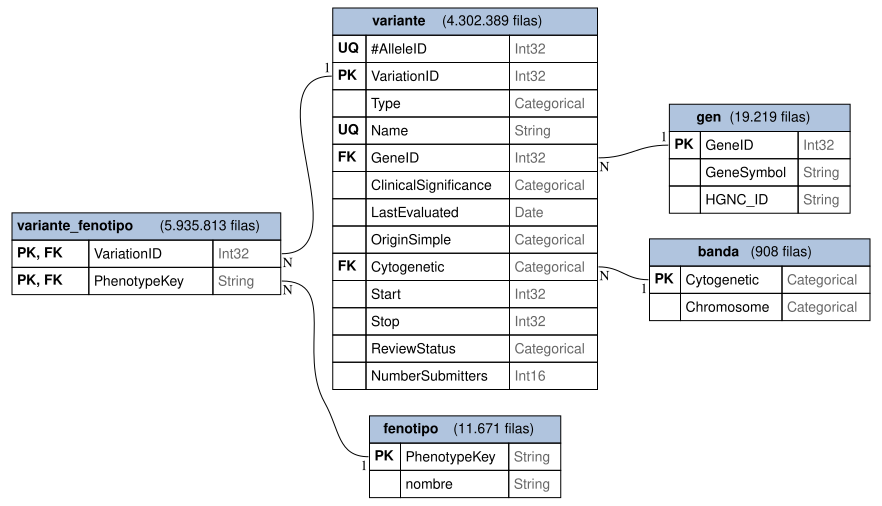

In [18]:
import graphviz
from html import escape

TABLAS = {"gen": gen, "variante": variante, "banda": banda,
          "variante_fenotipo": variante_fenotipo, "fenotipo": fenotipo}
CLAVES = {("gen", "GeneID"): "PK",
          ("variante", "VariationID"): "PK", ("variante", "#AlleleID"): "UQ", ("variante", "Name"): "UQ",
          ("variante", "GeneID"): "FK", ("variante", "Cytogenetic"): "FK",
          ("banda", "Cytogenetic"): "PK",
          ("variante_fenotipo", "VariationID"): "PK, FK", ("variante_fenotipo", "PhenotypeKey"): "PK, FK",
          ("fenotipo", "PhenotypeKey"): "PK"}
# (tabla del lado N, columna FK, tabla del lado 1, columna referenciada)
RELACIONES = [("variante", "GeneID", "gen", "GeneID"),
              ("variante", "Cytogenetic", "banda", "Cytogenetic"),
              ("variante_fenotipo", "VariationID", "variante", "VariationID"),
              ("variante_fenotipo", "PhenotypeKey", "fenotipo", "PhenotypeKey")]

def clave(nombre, col):
    marca = CLAVES.get((nombre, col))
    return f"<b>{marca}</b>" if marca else " "

def etiqueta(nombre, df):
    filas = "".join(
        f'<tr><td port="{col.strip("#")}_w" align="left">{clave(nombre, col)}</td>'
        f'<td align="left">{escape(col)}</td>'
        f'<td port="{col.strip("#")}_e" align="left"><font color="gray40">{dtype}</font></td></tr>'
        for col, dtype in df.schema.items())
    return (f'<<table border="0" cellborder="1" cellspacing="0" cellpadding="4">'
            f'<tr><td colspan="3" bgcolor="lightsteelblue"><b>{nombre}</b> ({f"{df.height:,}".replace(",", ".")} filas)</td></tr>{filas}</table>>')

er = graphviz.Digraph("ER", graph_attr={"rankdir": "LR"}, node_attr={"shape": "plaintext", "fontname": "Helvetica"})
for nombre, df in TABLAS.items():
    er.node(nombre, etiqueta(nombre, df))
for tabla_n, fk, tabla_1, pk in RELACIONES:
    # Sale por la derecha de la FK y entra por la izquierda de la PK
    er.edge(f"{tabla_n}:{fk}_e:e", f"{tabla_1}:{pk}_w:w", taillabel="N", headlabel="1", arrowhead="none")
er

### BCNF y 4NF

**BCNF**: todo determinante debe ser clave candidata.

| Tabla | Determinantes | ¿Son clave candidata? |
|---|---|---|
| `variante` | `VariationID`, `#AlleleID`, `Name` | ✅ |
| `gen` | `GeneID`, `GeneSymbol` | ✅ |
| `banda` | `Cytogenetic` | ✅ |
| `fenotipo` | `PhenotypeKey` | ✅ |
| `variante_fenotipo` | Solo la clave completa | ✅ |

**4NF**: no puede haber dependencias multivaluadas no triviales salvo sobre una clave. Aparecen cuando una tabla guarda dos listas independientes de la misma entidad (ej. fenotipos y orígenes de una variante en la misma tabla, que obliga a repetir todas las combinaciones). En este esquema no ocurre: `variante_fenotipo` tiene solo dos columnas, `Origin` (el otro atributo multivalor) se eliminó en la 1NF, y de los IDs de fenotipo se conservó solo MedGen (guardar también MONDO, OMIM y Orphanet en la misma tabla habría generado una).

El esquema cumple 1NF, 2NF, 3NF, BCNF y 4NF sin necesidad de tablas adicionales.

# Base de datos transaccional (SQLite)

El esquema en 4NF se carga en `clinvar_oltp.db` con las restricciones declaradas en el motor, no solo verificadas en Polars:

- **PK** en cada tabla y **PK compuesta** `(VariationID, PhenotypeKey)` en `variante_fenotipo`.
- **FK** `variante → gen`, `variante → banda`, `variante_fenotipo → variante / fenotipo`, con `PRAGMA foreign_keys = ON` (SQLite las ignora por defecto).
- **UNIQUE** en las otras claves candidatas (`AlleleID`, `Name`, `GeneSymbol`) y **NOT NULL** donde la limpieza garantizó que no hay faltantes. `LastEvaluated` y `fenotipo.nombre` admiten NULL porque el faltante es real (variante nunca evaluada, condición sin nombre).
- **Índices** sobre las FK no cubiertas por una PK, para que los joins no recorran la tabla entera.

Decisiones de tipos: `#AlleleID` se renombra a `AlleleID` (el `#` obliga a citar la columna en cada consulta) y las fechas se guardan como texto ISO 8601 (`YYYY-MM-DD`), el formato que entienden las funciones de fecha de SQLite. Las tablas se insertan de referenciadas a referenciantes dentro de una sola transacción, y al final se comparan los conteos con los DataFrames y se corre `PRAGMA foreign_key_check`.

In [19]:
import sqlite3
from pathlib import Path

OLTP_DB = Path("../data/processed/clinvar_oltp.db")
OLTP_DB.parent.mkdir(parents=True, exist_ok=True)
OLTP_DB.unlink(missing_ok=True)   # se regenera desde cero en cada corrida

DDL = """
CREATE TABLE gen (
    GeneID      INTEGER PRIMARY KEY,
    GeneSymbol  TEXT NOT NULL UNIQUE,
    HGNC_ID     TEXT NOT NULL
);
CREATE TABLE banda (
    Cytogenetic TEXT PRIMARY KEY,
    Chromosome  TEXT NOT NULL
);
CREATE TABLE fenotipo (
    PhenotypeKey TEXT PRIMARY KEY,
    nombre       TEXT
);
CREATE TABLE variante (
    VariationID          INTEGER PRIMARY KEY,
    AlleleID             INTEGER NOT NULL UNIQUE,
    Name                 TEXT    NOT NULL UNIQUE,
    Type                 TEXT    NOT NULL,
    GeneID               INTEGER NOT NULL REFERENCES gen(GeneID),
    Cytogenetic          TEXT    NOT NULL REFERENCES banda(Cytogenetic),
    Start                INTEGER NOT NULL,
    Stop                 INTEGER NOT NULL,
    ClinicalSignificance TEXT    NOT NULL,
    ReviewStatus         TEXT    NOT NULL,
    OriginSimple         TEXT    NOT NULL,
    LastEvaluated        TEXT,               -- fecha ISO 8601 (YYYY-MM-DD); NULL = nunca evaluada
    NumberSubmitters     INTEGER NOT NULL
);
CREATE TABLE variante_fenotipo (
    VariationID  INTEGER NOT NULL REFERENCES variante(VariationID),
    PhenotypeKey TEXT    NOT NULL REFERENCES fenotipo(PhenotypeKey),
    PRIMARY KEY (VariationID, PhenotypeKey)
);
-- Índices sobre las FK que no quedan cubiertas por una PK
CREATE INDEX ix_variante_gen   ON variante(GeneID);
CREATE INDEX ix_variante_banda ON variante(Cytogenetic);
CREATE INDEX ix_vf_fenotipo    ON variante_fenotipo(PhenotypeKey);
"""

# Mismo orden de columnas que en el DDL. Categorical y Date pasan a texto:
# SQLite no tiene tipo fecha y el adaptador automático de date está deprecado.
CARGA = {   # en orden: primero las tablas referenciadas, después las que tienen FK
    "gen": gen,
    "banda": banda,
    "fenotipo": fenotipo,
    "variante": variante.rename({"#AlleleID": "AlleleID"}),
    "variante_fenotipo": variante_fenotipo,
}

con = sqlite3.connect(OLTP_DB)
con.execute("PRAGMA foreign_keys = ON")
con.execute("PRAGMA cache_size = -2000000")  # 2 GB de caché: evita escribir a disco en cada inserción en los índices UNIQUE
con.executescript(DDL)

with con:   # una sola transacción: si algo falla no queda la base a medio cargar
    for tabla, df_t in CARGA.items():
        nombres = [c[1] for c in con.execute(f"PRAGMA table_info({tabla})")]
        df_t = df_t.select(nombres).with_columns(pl.col(pl.Categorical, pl.Date).cast(pl.String))
        con.executemany(f"INSERT INTO {tabla} VALUES ({', '.join('?' * len(nombres))})",
                        df_t.iter_rows())

# Verificación: filas iguales a los DataFrames y ninguna FK rota
for tabla, df_t in CARGA.items():
    n = con.execute(f"SELECT COUNT(*) FROM {tabla}").fetchone()[0]
    assert n == df_t.height, (tabla, n, df_t.height)
    print(f"{tabla:<18} {n:>10,} filas")
assert con.execute("PRAGMA foreign_key_check").fetchall() == []
print(f"\nFK sin violaciones | tamaño: {OLTP_DB.stat().st_size / 1e6:,.0f} MB")

gen                    19,219 filas
banda                     908 filas
fenotipo               11,671 filas
variante            4,302,389 filas
variante_fenotipo   5,935,813 filas



FK sin violaciones | tamaño: 1,683 MB


In [20]:
# Consulta de prueba: genes con más variantes patogénicas (une las 3 tablas principales)
pl.read_database(
    """SELECT g.GeneSymbol, b.Chromosome, COUNT(*) AS patogenicas
       FROM variante v
       JOIN gen   g USING (GeneID)
       JOIN banda b USING (Cytogenetic)
       WHERE v.ClinicalSignificance IN ('Pathogenic', 'Likely pathogenic', 'Pathogenic/Likely pathogenic')
       GROUP BY g.GeneSymbol, b.Chromosome
       ORDER BY patogenicas DESC
       LIMIT 10""", con)

GeneSymbol,Chromosome,patogenicas
str,str,i64
"""TTN""","""2""",5921
"""BRCA2""","""13""",5756
"""NF1""","""17""",5675
"""BRCA1""","""17""",4294
"""ATM""","""11""",3861
"""FBN1""","""15""",3720
"""APC""","""5""",2629
"""DMD""","""X""",2433
"""PKD1""","""16""",2412


# Almacén de datos: esquema copo de nieve

El almacén `clinvar_dw.db` se carga **desde la base transaccional** (`clinvar_oltp.db` adjuntada en solo lectura con `ATTACH`), no desde los DataFrames, así el flujo ETL queda completo: fuente → OLTP → almacén. Toda la transformación se hace en SQL con `INSERT … SELECT`.

**Grano de la tabla de hechos:** una fila por variante de ClinVar (`VariationID`).

| Tabla | Rol | Contenido |
|---|---|---|
| `fact_variante` | Hechos | Claves de las 7 dimensiones + medidas: `n_remitentes`, `largo_pb` (`Stop − Start + 1`), `n_fenotipos`, `es_patogenica` (0/1, se suma directo para obtener proporciones). `VariationID` queda como dimensión degenerada |
| `dim_banda` → `dim_cromosoma` | Dimensión normalizada (**copo de nieve**) | Banda citogenética y brazo (p / q / p-q); el cromosoma con su tipo (autosoma, sexual, mitocondrial) y un orden numérico para graficar 1…22, X, Y, MT |
| `dim_clasificacion` → `dim_categoria` | Dimensión normalizada (**copo de nieve**) | Las 40 clasificaciones de ClinVar agrupadas en 6 categorías |
| `dim_gen`, `dim_tipo`, `dim_revision`, `dim_origen` | Dimensiones | Gen; tipo de variante y su clase; estado de revisión y sus estrellas; origen |
| `dim_fecha` | Dimensión de tiempo | Fecha de última evaluación desglosada en año, trimestre y mes. Las variantes nunca evaluadas apuntan a la fila `0` en lugar de NULL |
| `puente_variante_fenotipo` → `dim_fenotipo` | Tabla puente | La relación variante–fenotipo es N:M y no puede ir como FK en los hechos |

**Claves sustitutas.** Cada dimensión tiene una clave entera propia (`*_key`) separada del identificador de negocio (`GeneID`, `Cytogenetic`, …), que se conserva como atributo. Así el almacén no depende de cómo ClinVar codifica sus IDs.

**Atributos derivados:**

| Atributo | Regla |
|---|---|
| `categoria` | *Pathogenic* / *Likely pathogenic* (incluidas las de baja penetrancia) → **Patogénica**; *Benign* / *Likely benign* → **Benigna**; *Uncertain significance* y *VUS-low/mid/high* → **VUS**; clasificaciones en conflicto → **Conflicto**; *Sin clasificación*; el resto (respuesta a fármacos, factor de riesgo, asociación, protectora…) → **Otra** |
| `estrellas` | Escala oficial de ClinVar: *practice guideline* = 4, *reviewed by expert panel* = 3, *multiple submitters, no conflicts* = 2, *single submitter* o *conflicting classifications* = 1, sin criterios = 0 |
| `clase` | SNV; *Deletion / Duplication / Insertion / Indel* → Inserción-deleción; *Microsatellite* → Repetición; *Inversion* y CNV → Estructural; *Variation* → Otra |
| `brazo` | `p` o `q` según la banda; `p-q` si el rango cruza el centrómero (ej. `Xp11.21-q12`); `MT` para el mitocondrial |

**Validaciones** al final de la carga: los hechos y el puente tienen exactamente las mismas filas que `variante` y `variante_fenotipo` en la OLTP, la suma de remitentes coincide, `n_fenotipos` cuadra con el puente, las fechas nulas fueron a la clave `0` y no hay FK rotas.

In [21]:
import sqlite3
from pathlib import Path

OLTP_DB = Path("../data/processed/clinvar_oltp.db")
DW_DB = Path("../data/processed/clinvar_dw.db")
DW_DB.unlink(missing_ok=True)   # se regenera desde cero en cada corrida

DDL_DW = """
-- Jerarquía banda -> cromosoma (copo de nieve)
CREATE TABLE dim_cromosoma (
    cromosoma_key INTEGER PRIMARY KEY,
    Chromosome    TEXT    NOT NULL UNIQUE,
    tipo          TEXT    NOT NULL,          -- Autosoma / Sexual / Mitocondrial
    orden         INTEGER NOT NULL           -- 1..22, X = 23, Y = 24, MT = 25 (para ordenar gráficos)
);
CREATE TABLE dim_banda (
    banda_key     INTEGER PRIMARY KEY,
    Cytogenetic   TEXT NOT NULL UNIQUE,
    brazo         TEXT NOT NULL,             -- p / q / p-q (abarca el centrómero) / MT
    cromosoma_key INTEGER NOT NULL REFERENCES dim_cromosoma(cromosoma_key)
);
-- Jerarquía clasificación -> categoría (copo de nieve)
CREATE TABLE dim_categoria (
    categoria_key INTEGER PRIMARY KEY,
    categoria     TEXT NOT NULL UNIQUE
);
CREATE TABLE dim_clasificacion (
    clasif_key           INTEGER PRIMARY KEY,
    ClinicalSignificance TEXT    NOT NULL UNIQUE,
    categoria_key        INTEGER NOT NULL REFERENCES dim_categoria(categoria_key)
);
CREATE TABLE dim_gen (
    gen_key    INTEGER PRIMARY KEY,
    GeneID     INTEGER NOT NULL UNIQUE,
    GeneSymbol TEXT    NOT NULL,
    HGNC_ID    TEXT    NOT NULL
);
CREATE TABLE dim_revision (
    revision_key INTEGER PRIMARY KEY,
    ReviewStatus TEXT    NOT NULL UNIQUE,
    estrellas    INTEGER NOT NULL            -- escala oficial de ClinVar (0 a 4)
);
CREATE TABLE dim_tipo (
    tipo_key INTEGER PRIMARY KEY,
    Type     TEXT NOT NULL UNIQUE,
    clase    TEXT NOT NULL                   -- SNV / Inserción-deleción / Repetición / Estructural / Otra
);
CREATE TABLE dim_origen (
    origen_key   INTEGER PRIMARY KEY,
    OriginSimple TEXT NOT NULL UNIQUE
);
CREATE TABLE dim_fecha (
    fecha_key  INTEGER PRIMARY KEY,          -- AAAAMMDD; 0 = nunca evaluada
    fecha      TEXT,
    anio       INTEGER,
    trimestre  INTEGER,
    mes        INTEGER
);
CREATE TABLE dim_fenotipo (
    fenotipo_key INTEGER PRIMARY KEY,
    PhenotypeKey TEXT NOT NULL UNIQUE,
    nombre       TEXT
);
-- Hechos: una fila por variante
CREATE TABLE fact_variante (
    VariationID    INTEGER PRIMARY KEY,      -- dimensión degenerada
    gen_key        INTEGER NOT NULL REFERENCES dim_gen(gen_key),
    banda_key      INTEGER NOT NULL REFERENCES dim_banda(banda_key),
    clasif_key     INTEGER NOT NULL REFERENCES dim_clasificacion(clasif_key),
    revision_key   INTEGER NOT NULL REFERENCES dim_revision(revision_key),
    tipo_key       INTEGER NOT NULL REFERENCES dim_tipo(tipo_key),
    origen_key     INTEGER NOT NULL REFERENCES dim_origen(origen_key),
    fecha_eval_key INTEGER NOT NULL REFERENCES dim_fecha(fecha_key),
    n_remitentes   INTEGER NOT NULL,
    largo_pb       INTEGER NOT NULL,
    n_fenotipos    INTEGER NOT NULL,
    es_patogenica  INTEGER NOT NULL CHECK (es_patogenica IN (0, 1))
);
-- Puente N:M entre hechos y fenotipos
CREATE TABLE puente_variante_fenotipo (
    VariationID  INTEGER NOT NULL REFERENCES fact_variante(VariationID),
    fenotipo_key INTEGER NOT NULL REFERENCES dim_fenotipo(fenotipo_key),
    PRIMARY KEY (VariationID, fenotipo_key)
);
CREATE INDEX ix_fact_gen       ON fact_variante(gen_key);
CREATE INDEX ix_fact_banda     ON fact_variante(banda_key);
CREATE INDEX ix_fact_clasif    ON fact_variante(clasif_key);
CREATE INDEX ix_fact_revision  ON fact_variante(revision_key);
CREATE INDEX ix_fact_tipo      ON fact_variante(tipo_key);
CREATE INDEX ix_fact_fecha     ON fact_variante(fecha_eval_key);
CREATE INDEX ix_puente_fenotipo ON puente_variante_fenotipo(fenotipo_key);
"""

# Cada dimensión se arma con SELECT DISTINCT sobre la base OLTP (adjuntada como esquema "oltp").
# Las claves sustitutas las asigna SQLite (INTEGER PRIMARY KEY) en el orden del ORDER BY.
CARGA_DW = [
    ("dim_cromosoma", """
        INSERT INTO dim_cromosoma (Chromosome, tipo, orden)
        SELECT Chromosome,
               CASE WHEN Chromosome IN ('X', 'Y') THEN 'Sexual'
                    WHEN Chromosome = 'MT' THEN 'Mitocondrial' ELSE 'Autosoma' END,
               CASE Chromosome WHEN 'X' THEN 23 WHEN 'Y' THEN 24 WHEN 'MT' THEN 25
                    ELSE CAST(Chromosome AS INTEGER) END AS orden
        FROM (SELECT DISTINCT Chromosome FROM oltp.banda) ORDER BY orden"""),
    ("dim_banda", """
        INSERT INTO dim_banda (Cytogenetic, brazo, cromosoma_key)
        SELECT b.Cytogenetic,
               CASE WHEN b.Cytogenetic = 'MT' THEN 'MT'
                    WHEN b.Cytogenetic LIKE '%p%' AND b.Cytogenetic LIKE '%q%' THEN 'p-q'
                    WHEN b.Cytogenetic LIKE '%p%' THEN 'p' ELSE 'q' END,
               c.cromosoma_key
        FROM oltp.banda b JOIN dim_cromosoma c USING (Chromosome)
        ORDER BY c.orden, b.Cytogenetic"""),
    ("dim_categoria", """
        INSERT INTO dim_categoria (categoria) VALUES
            ('Patogénica'), ('Benigna'), ('VUS'), ('Conflicto'), ('Otra'), ('Sin clasificación')"""),
    ("dim_clasificacion", """
        INSERT INTO dim_clasificacion (ClinicalSignificance, categoria_key)
        SELECT s.ClinicalSignificance, c.categoria_key
        FROM (SELECT DISTINCT ClinicalSignificance,
                     CASE WHEN ClinicalSignificance LIKE 'Pathogenic%'
                            OR ClinicalSignificance LIKE 'Likely pathogenic%'      THEN 'Patogénica'
                          WHEN ClinicalSignificance IN ('Benign', 'Likely benign',
                                                        'Benign/Likely benign')    THEN 'Benigna'
                          WHEN ClinicalSignificance LIKE 'Uncertain significance%'
                            OR ClinicalSignificance LIKE 'VUS-%'                   THEN 'VUS'
                          WHEN ClinicalSignificance LIKE 'Conflicting%'
                            OR ClinicalSignificance LIKE 'conflicting%'            THEN 'Conflicto'
                          WHEN ClinicalSignificance = 'Sin clasificación'          THEN 'Sin clasificación'
                          ELSE 'Otra' END AS categoria
              FROM oltp.variante) s
        JOIN dim_categoria c USING (categoria)
        ORDER BY c.categoria_key, s.ClinicalSignificance"""),
    ("dim_gen", """
        INSERT INTO dim_gen (GeneID, GeneSymbol, HGNC_ID)
        SELECT GeneID, GeneSymbol, HGNC_ID FROM oltp.gen ORDER BY GeneSymbol"""),
    ("dim_revision", """
        INSERT INTO dim_revision (ReviewStatus, estrellas)
        SELECT ReviewStatus,
               CASE ReviewStatus
                    WHEN 'practice guideline'                                   THEN 4
                    WHEN 'reviewed by expert panel'                             THEN 3
                    WHEN 'criteria provided, multiple submitters, no conflicts' THEN 2
                    WHEN 'criteria provided, single submitter'                  THEN 1
                    WHEN 'criteria provided, conflicting classifications'       THEN 1
                    ELSE 0 END AS estrellas
        FROM (SELECT DISTINCT ReviewStatus FROM oltp.variante)
        ORDER BY estrellas DESC, ReviewStatus"""),
    ("dim_tipo", """
        INSERT INTO dim_tipo (Type, clase)
        SELECT Type,
               CASE WHEN Type = 'single nucleotide variant'                         THEN 'SNV'
                    WHEN Type IN ('Deletion', 'Duplication', 'Insertion', 'Indel')  THEN 'Inserción-deleción'
                    WHEN Type = 'Microsatellite'                                    THEN 'Repetición'
                    WHEN Type IN ('Inversion', 'copy number loss', 'copy number gain') THEN 'Estructural'
                    ELSE 'Otra' END
        FROM (SELECT DISTINCT Type FROM oltp.variante) ORDER BY Type"""),
    ("dim_origen", """
        INSERT INTO dim_origen (OriginSimple)
        SELECT DISTINCT OriginSimple FROM oltp.variante ORDER BY OriginSimple"""),
    ("dim_fecha", """
        INSERT INTO dim_fecha (fecha_key, fecha, anio, trimestre, mes)
        SELECT 0, NULL, NULL, NULL, NULL
        UNION ALL
        SELECT CAST(strftime('%Y%m%d', f) AS INTEGER), f,
               CAST(strftime('%Y', f) AS INTEGER),
               (CAST(strftime('%m', f) AS INTEGER) + 2) / 3,
               CAST(strftime('%m', f) AS INTEGER)
        FROM (SELECT DISTINCT LastEvaluated AS f FROM oltp.variante WHERE f IS NOT NULL)
        ORDER BY 1"""),
    ("dim_fenotipo", """
        INSERT INTO dim_fenotipo (PhenotypeKey, nombre)
        SELECT PhenotypeKey, nombre FROM oltp.fenotipo ORDER BY PhenotypeKey"""),
    ("fact_variante", """
        INSERT INTO fact_variante
        SELECT v.VariationID, g.gen_key, b.banda_key, cl.clasif_key, r.revision_key, t.tipo_key,
               o.origen_key,
               COALESCE(CAST(strftime('%Y%m%d', v.LastEvaluated) AS INTEGER), 0),
               v.NumberSubmitters,
               v.Stop - v.Start + 1,
               (SELECT COUNT(*) FROM oltp.variante_fenotipo vf WHERE vf.VariationID = v.VariationID),
               cat.categoria = 'Patogénica'
        FROM oltp.variante v
        JOIN dim_gen           g   ON g.GeneID = v.GeneID
        JOIN dim_banda         b   ON b.Cytogenetic = v.Cytogenetic
        JOIN dim_clasificacion cl  ON cl.ClinicalSignificance = v.ClinicalSignificance
        JOIN dim_categoria     cat ON cat.categoria_key = cl.categoria_key
        JOIN dim_revision      r   ON r.ReviewStatus = v.ReviewStatus
        JOIN dim_tipo          t   ON t.Type = v.Type
        JOIN dim_origen        o   ON o.OriginSimple = v.OriginSimple
        ORDER BY v.VariationID"""),
    ("puente_variante_fenotipo", """
        INSERT INTO puente_variante_fenotipo
        SELECT vf.VariationID, f.fenotipo_key
        FROM oltp.variante_fenotipo vf JOIN dim_fenotipo f USING (PhenotypeKey)
        ORDER BY vf.VariationID, f.fenotipo_key"""),
]

dw = sqlite3.connect(f"file:{DW_DB}", uri=True)   # modo URI: permite adjuntar la OLTP con ?mode=ro
dw.execute("PRAGMA foreign_keys = ON")
dw.execute("PRAGMA cache_size = -2000000")   # 2 GB, igual que en la carga OLTP
dw.executescript(DDL_DW)
dw.execute(f"ATTACH DATABASE 'file:{OLTP_DB}?mode=ro' AS oltp")   # solo lectura: el ETL no toca la OLTP
dw.execute("PRAGMA oltp.cache_size = -2000000")

with dw:   # una sola transacción
    for tabla, sql in CARGA_DW:
        n = dw.execute(sql).rowcount
        print(f"{tabla:<26} {n:>10,} filas")

# Verificaciones contra la OLTP: no se pierde ni se duplica ninguna fila
chequeos = {
    "hechos = variantes OLTP":
        "SELECT (SELECT COUNT(*) FROM fact_variante) = (SELECT COUNT(*) FROM oltp.variante)",
    "puente = variante_fenotipo OLTP":
        "SELECT (SELECT COUNT(*) FROM puente_variante_fenotipo) = (SELECT COUNT(*) FROM oltp.variante_fenotipo)",
    "suma de remitentes igual":
        "SELECT (SELECT SUM(n_remitentes) FROM fact_variante) = (SELECT SUM(NumberSubmitters) FROM oltp.variante)",
    "n_fenotipos coincide con el puente":
        "SELECT (SELECT SUM(n_fenotipos) FROM fact_variante) = (SELECT COUNT(*) FROM puente_variante_fenotipo)",
    "fechas nulas -> clave 0":
        "SELECT (SELECT COUNT(*) FROM fact_variante WHERE fecha_eval_key = 0) "
        "     = (SELECT COUNT(*) FROM oltp.variante WHERE LastEvaluated IS NULL)",
}
for nombre, sql in chequeos.items():
    assert dw.execute(sql).fetchone()[0] == 1, nombre
    print(f"✅ {nombre}")
assert dw.execute("PRAGMA foreign_key_check").fetchall() == []
print("✅ sin violaciones de FK")
dw.execute("DETACH DATABASE oltp")
print(f"\nTamaño: {DW_DB.stat().st_size / 1e6:,.0f} MB")

dim_cromosoma                      25 filas
dim_banda                         908 filas
dim_categoria                       6 filas


dim_clasificacion                  40 filas
dim_gen                        19,219 filas


dim_revision                        7 filas


dim_tipo                           10 filas


dim_origen                          5 filas


dim_fecha                       6,695 filas
dim_fenotipo                   11,671 filas


... (5 outputs left out)

✅ n_fenotipos coincide con el puente


✅ fechas nulas -> clave 0


✅ sin violaciones de FK



Tamaño: 714 MB


### Diagrama del copo de nieve

Naranja: hechos · amarillo: puente · azul: dimensiones. `dim_cromosoma` y `dim_categoria` (a la derecha) son el segundo nivel de normalización que convierte la estrella en copo de nieve; `dim_fenotipo` se alcanza a través de la tabla puente.

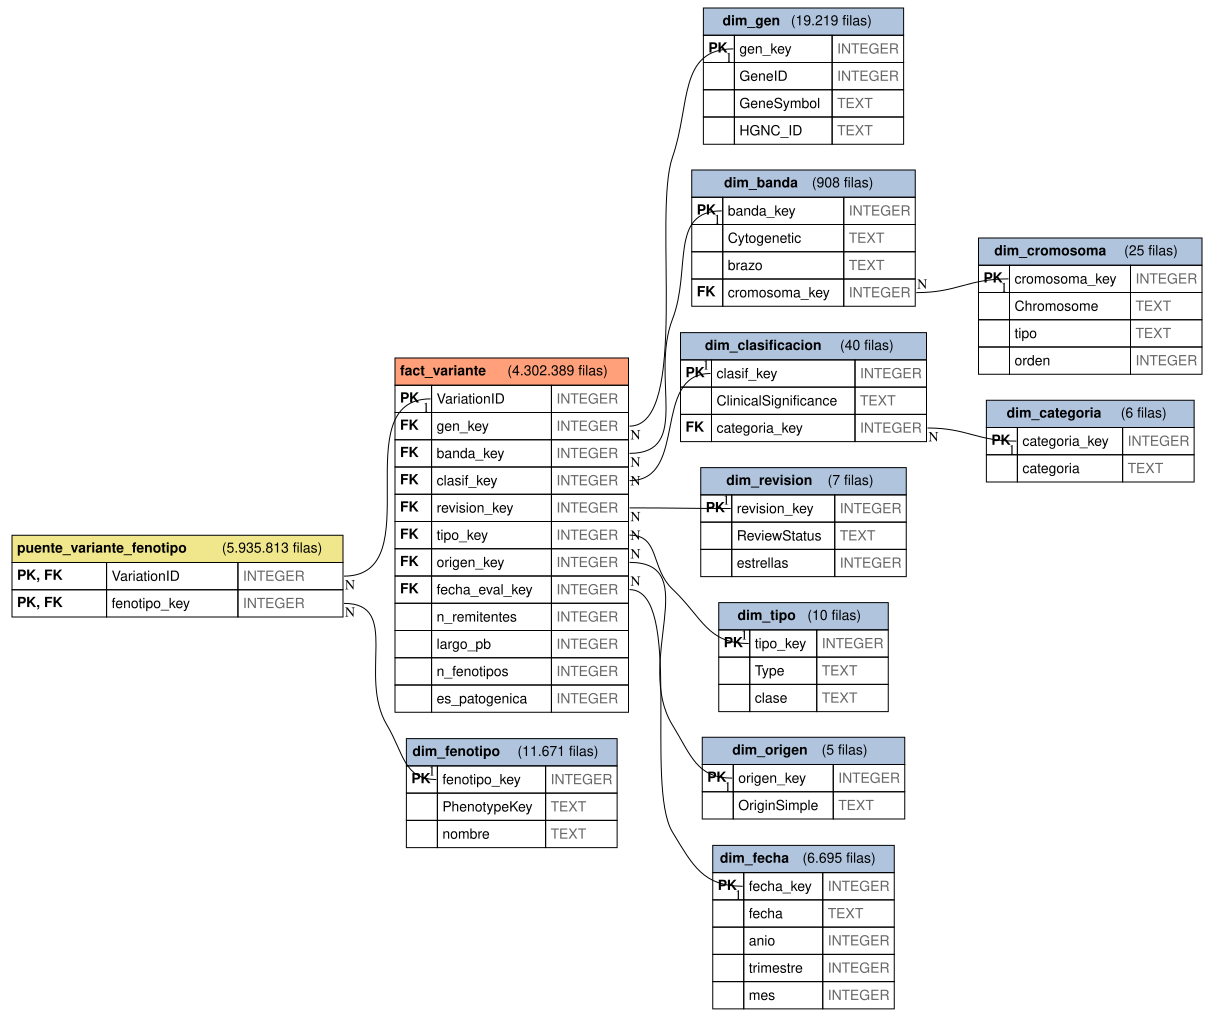

In [22]:
# Diagrama generado desde el esquema real de clinvar_dw.db (PRAGMA table_info / foreign_key_list)
COLOR = {"fact": "lightsalmon", "puente": "khaki", "dim": "lightsteelblue"}

def nodo_dw(tabla):
    fks = {fk[3] for fk in dw.execute(f"PRAGMA foreign_key_list({tabla})")}
    n = dw.execute(f"SELECT COUNT(*) FROM {tabla}").fetchone()[0]
    def marca(col, pk):   # Graphviz no acepta <b></b> vacío
        m = ", ".join(x for x, ok in [("PK", pk), ("FK", col in fks)] if ok)
        return f"<b>{m}</b>" if m else " "
    filas = "".join(
        f'<tr><td align="left">{marca(col, pk)}</td>'
        f'<td port="{col}_w" align="left">{escape(col)}</td>'
        f'<td port="{col}_e" align="left"><font color="gray40">{tipo}</font></td></tr>'
        for _, col, tipo, _, _, pk in dw.execute(f"PRAGMA table_info({tabla})"))
    color = COLOR[tabla.split("_")[0]]
    return (f'<<table border="0" cellborder="1" cellspacing="0" cellpadding="4">'
            f'<tr><td colspan="3" bgcolor="{color}"><b>{tabla}</b> ({f"{n:,}".replace(",", ".")} filas)</td></tr>{filas}</table>>')

tablas_dw = [t for (t,) in dw.execute("SELECT name FROM sqlite_master WHERE type = 'table' ORDER BY name")]
snow = graphviz.Digraph("DW", graph_attr={"rankdir": "LR"}, node_attr={"shape": "plaintext", "fontname": "Helvetica"})
for t in tablas_dw:
    snow.node(t, nodo_dw(t))
    for _, _, ref, col, ref_col, *_ in dw.execute(f"PRAGMA foreign_key_list({t})"):
        snow.edge(f"{t}:{col}_e:e", f"{ref}:{ref_col}_w:w", taillabel="N", headlabel="1", arrowhead="none")
snow

In [23]:
# Consulta analítica que recorre el copo de nieve: hechos -> banda -> cromosoma
pl.read_database(
    """SELECT c.Chromosome, c.tipo,
              COUNT(*)                                        AS variantes,
              SUM(f.es_patogenica)                            AS patogenicas,
              ROUND(100.0 * SUM(f.es_patogenica) / COUNT(*), 1) AS pct_patogenicas
       FROM fact_variante f
       JOIN dim_banda     b USING (banda_key)
       JOIN dim_cromosoma c USING (cromosoma_key)
       GROUP BY c.cromosoma_key
       ORDER BY c.orden""", dw)

Chromosome,tipo,variantes,patogenicas,pct_patogenicas
str,str,i64,i64,f64
"""1""","""Autosoma""",388465,26799,6.9
"""2""","""Autosoma""",380897,38022,10.0
"""3""","""Autosoma""",235438,17992,7.6
"""4""","""Autosoma""",153466,9594,6.3
"""5""","""Autosoma""",210293,16646,7.9
"""6""","""Autosoma""",193173,15843,8.2
"""7""","""Autosoma""",210747,15346,7.3
"""8""","""Autosoma""",145913,11082,7.6
"""9""","""Autosoma""",192921,14117,7.3
